<a href="https://colab.research.google.com/github/Sameer1098/colab-tutorials/blob/main/T9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Kernel comparison ===
 linear kernel accuracy: 0.982
   poly kernel accuracy: 0.895
    rbf kernel accuracy: 0.977

=== GridSearchCV (RBF kernel) ===
Best params: {'svc__C': 10, 'svc__gamma': 0.001}
Best CV accuracy: 0.980
Test accuracy: 0.971
Confusion matrix:
 [[ 60   4]
 [  1 106]]
              precision    recall  f1-score   support

   malignant       0.98      0.94      0.96        64
      benign       0.96      0.99      0.98       107

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171



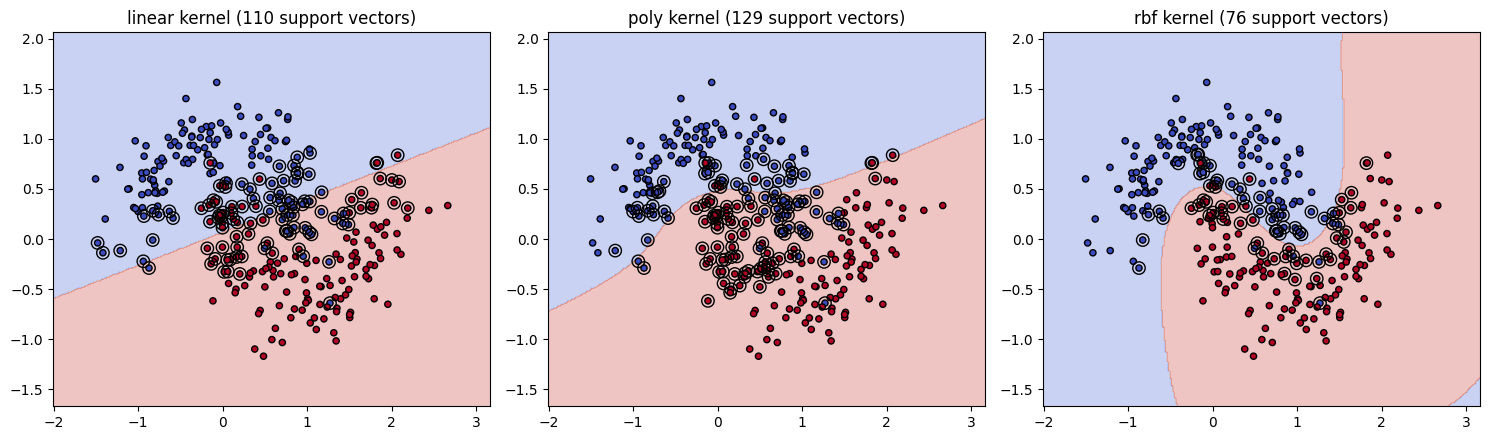

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, make_moons
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Load data
data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.3, random_state=42, stratify=data.target)

# 2. Compare kernels
print("=== Kernel comparison ===")
for kernel in ["linear", "poly", "rbf"]:
    model = make_pipeline(StandardScaler(), SVC(kernel=kernel, C=1.0))
    model.fit(X_train, y_train)
    acc = accuracy_score(y_test, model.predict(X_test))
    print(f"{kernel:>7} kernel accuracy: {acc:.3f}")

# 3. Hyperparameter tuning
print("\n=== GridSearchCV (RBF kernel) ===")
pipe = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
grid = GridSearchCV(pipe,
                    {"svc__C": [0.1, 1, 10, 100],
                     "svc__gamma": [0.001, 0.01, 0.1, 1]},
                    cv=5, n_jobs=-1)
grid.fit(X_train, y_train)
print("Best params:", grid.best_params_)
print("Best CV accuracy: %.3f" % grid.best_score_)

best = grid.best_estimator_
pred = best.predict(X_test)
print("Test accuracy: %.3f" % accuracy_score(y_test, pred))
print("Confusion matrix:\n", confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, target_names=data.target_names))

# 4. Decision boundaries on 2-D data
Xm, ym = make_moons(n_samples=300, noise=0.25, random_state=0)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
xx, yy = np.meshgrid(np.linspace(Xm[:, 0].min() - .5, Xm[:, 0].max() + .5, 300),
                     np.linspace(Xm[:, 1].min() - .5, Xm[:, 1].max() + .5, 300))
for ax, kernel in zip(axes, ["linear", "poly", "rbf"]):
    clf = SVC(kernel=kernel, C=1.0, gamma="scale").fit(Xm, ym)
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(Xm[:, 0], Xm[:, 1], c=ym, cmap="coolwarm", edgecolor="k", s=20)
    ax.scatter(*clf.support_vectors_.T, s=80, facecolors="none", edgecolors="k")
    ax.set_title(f"{kernel} kernel ({len(clf.support_vectors_)} support vectors)")
plt.tight_layout()
plt.show()